# Extract Quality Spectra of Tree Crowns from AVIRIS-3 Reflectance

## Overview

**[AVUELO](https://www.earthdata.nasa.gov/data/projects/avuelo)** project mapped tree crowns in several forest plots in Panama from high-resolution UAV orthomosaics, and identified the species of each tree crown on the ground ([Arauz et al., 2026](https://doi.org/10.3334/ORNLDAAC/2517)). In February 2025, AVIRIS-3 imaged the same forests at high-resolution.

In this tutorial, we use the crown polygons to extract AVIRIS-3 surface reflectance spectra for individual trees in a plot. We will:

1. get the AVUELO tree crown polygons
2. spatially subset an AVIRIS-3 L2A reflectance scene and its uncertainty to the crowns
3. apply pixel-level and crown-level quality filters
4. extract mean spectra for each crown and compare species
5. export the spectra for further analysis

## Requirements

- A NASA [Earthdata Login](https://urs.earthdata.nasa.gov/) account
- See the [prerequisites](../../docs/prerequisites.md) page for setup instructions.

## Import Libraries

In [1]:
import earthaccess
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import rioxarray
import pyproj
import matplotlib.pyplot as plt
from shapely.geometry import box
from rasterio import features
from concurrent.futures import ThreadPoolExecutor
import warnings
warnings.filterwarnings('ignore')

# ESRI basemap for interactive maps
xyz = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
attr = "ESRI"

## Authentication

In [2]:
auth = earthaccess.login()

## Tree Crown Polygons

The [AVUELO tree crown dataset](https://doi.org/10.3334/ORNLDAAC/2517)(doi:10.3334/ORNLDAAC/2517) has one GeoPackage file with all crown polygons, and three orthomosaics. We search for the GeoPackage by the dataset DOI and open the `gpkg` file.

In [3]:
granules = earthaccess.search_data(doi='10.3334/ORNLDAAC/2517',
                                   granule_name='*.gpkg')
crowns = gpd.read_file(earthaccess.open(granules)[0])
print(f"CRS: {crowns.crs}\nNumber of tree crowns: {len(crowns)}")
crowns.head(3)

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

CRS: EPSG:32617
Number of tree crowns: 7688


,Plot_tag,Plot,Tag,Sp6,Sp4,SpeciesName,Crown,Illumination,Liana,Mature_leaves,...,Area_m2,Dbh_mm,Hom_m,Avuelo_sample_id,Collector,Census_date_2025,Dataset_CrownLightLiana,Census_date_CrownLightLiana,Global_id,geometry
0,ava_1010,ava,1010.0,MICOAR,MIC2,Miconia argentea,4.0,4.0,0.0,Complete,...,40.37,264.0,1.3,-9999.0,Melvin Hernandez,2025-09-17,Crownmap_2025,2025-09-17,33f09d66-0f17-4d14-b719-7e499703a169,"POLYGON ((626426.752 1012440.243, 626427.299 1..."
1,ava_1014,ava,1014.0,OCHRPY,OCHP,Ochroma pyramidale,4.0,4.0,0.0,Complete,...,143.58,549.0,1.3,-9999.0,Adrian Agrazal,2025-09-17,Crownmap_2025,2025-09-17,38964900-4062-4e81-99ef-0c342e5a720b,"POLYGON ((626549.554 1012552.901, 626549.736 1..."
2,ava_1020,ava,1020.0,VIROSE,VIR1,Virola sebifera,4.0,4.0,0.0,Complete,...,30.08,280.0,1.3,-9999.0,Fernando Arauz,2025-09-17,Crownmap_2025,2025-09-17,42be800f-36b3-4949-aac2-3a1b50c256c4,"POLYGON ((626502.279 1012412.096, 626502.644 1..."


Each polygon is the outline of a tree crown, linked to a tagged tree in the forest census. The attributes used in this tutorial are:

| Attribute | Description |
|---|---|
| `Plot_tag` | Unique tree ID: plot code and tag number |
| `Plot` | Plot code |
| `SpeciesName` | Scientific name of the tree |
| `Crown` | Crown intactness: 1 (0–25% intact) to 4 (75–100% intact) |
| `Illumination` | Crown light exposure: 1 (no direct light) to 5 (completely exposed to vertical and lateral light) |
| `Liana` | Crown covered by Liana or hemiepiphytes: 0 (none), 1 (1–25%), 2 (26–50%), 3 (51–75%), 4 (76–100%) |
| `Area_m2` | Crown area (m2) |

Missing values are coded -9999. See the [user guide](https://data.ornldaac.earthdata.nasa.gov/public/avuelo/TreeCrowns_Species_Panama/comp/TreeCrowns_Species_Panama.pdf) for all attributes.

We select the crowns in the `gigante` plot.

In [4]:
gigante = crowns[crowns.Plot == 'gigante'].copy()
print(f"Tree Crowns in the gigante plot: {len(gigante)}")
print(f"No. of species: {gigante.SpeciesName.nunique()}")
print(f"Top ten species:")
gigante.SpeciesName.value_counts().head(10)

Tree Crowns in the gigante plot: 2004
No. of species: 121
Top ten species:


SpeciesName
Protium stevensonii      233
Prioria copaifera        190
Jacaranda copaia         112
Dipteryx oleifera        101
Dialium guianense         96
Vatairea erythrocarpa     92
Alseis blackiana          83
Apeiba membranacea        66
Simarouba amara           64
Handroanthus guayacan     59
Name: count, dtype: int64

## Search AVIRIS-3 reflectance
We search the granules for the `AVUELO_AV3_L2A_Reflectance_2479` reflectance file files that overlaps the bounds of the gigante plot.

In [5]:
granules = earthaccess.search_data(short_name='AVUELO_AV3_L2A_Reflectance_2479',
                                         granule_name='*RFL_ORT.nc',
                                         bounding_box=tuple(gigante.to_crs(epsg=4326).total_bounds) )
print(f"Total granules overlapping gigante: {len(granules)}")

Total granules overlapping gigante: 15


In the following section, we compute pixel size of each of the granules without downloading the granules themselves. Please refer to **Tutorial 1** for more details.

In [6]:
def granule_details(g):
    """Returns AVIRIS-3 granule metadata as a dictionary."""
    name = g['umm']['GranuleUR'].split('.', 1)[1]
    parts = name.split('_')
    return {
        'scene_id': f"{parts[0]}_{parts[1]}",
        'size_mb': round(g['size']),
        'url': g.data_links()[0],
    }

def pixel_size(f):
    """Returns pixel size (m)."""
    da = xr.open_datatree(f, engine='h5netcdf')
    # pixel size as difference of two adjacent eastings
    pixel_size = float(da['easting'].diff('easting')[0])
    return pixel_size
   
# create a geopandas dataframe from granule details
gdf = gpd.GeoDataFrame([granule_details(g) for g in granules],
                       geometry=gpd.GeoSeries(granules, crs='EPSG:4326'))

files = earthaccess.open(list(gdf.url))
# parallel processing scene_info function over multithreads
with ThreadPoolExecutor(max_workers=4) as pool:
    info = list(pool.map(pixel_size, files))

# adding results as new columns to the dataframe

gdf['pixel_size_m'] = [round(i, 1) for i in info]
gdf[['scene_id', 'size_mb', 'pixel_size_m']]

QUEUEING TASKS | :   0%|          | 0/15 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/15 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/15 [00:00<?, ?it/s]

,scene_id,size_mb,pixel_size_m
0,AV320250206t194805_009,1141,3.4
1,AV320250206t200108_007,1018,3.4
2,AV320250206t200108_008,1024,3.4
3,AV320250206t201415_007,1134,3.4
4,AV320250210t161307_008,1032,3.4
5,AV320250210t162536_006,1062,3.4
6,AV320250210t162536_007,1055,3.4
7,AV320250210t163840_009,1044,3.4
8,AV320250210t163840_010,1043,3.4
9,AV320250226t180418_009,1080,1.1


As we see in the above table, there are some scenes with 1.1 m and some sciences with 3.3-3.4 m pixel size. We plot the scenes with 1.1 m pixel size that overlays the gigante plot. 

As the tree crown outlines are very detailed, we simplify them to a tolerance of 0.25 m only for the interactive map below, which keeps the map small. We use the original outlines for the analysis.

In [7]:
# plotting only pixel size 1.1m
m = gdf[gdf.pixel_size_m==1.1].explore(column='scene_id',tiles=xyz, attr=attr, tooltip=['scene_id'],
                style_kwds={'fillOpacity': 0.5, 'weight': 1})
# copy dataframe for plotting
gigante_map = gigante[['Plot_tag', 'SpeciesName', 'Crown', 'Illumination', 'Liana', 'Area_m2', 'geometry']].copy()
# simplify crown vertices
gigante_map['geometry'] = gigante_map.geometry.simplify(0.25)
# ploting the tree crowns
gigante_map.to_crs(epsg=4326).explore(m=m, column='Illumination', cmap='viridis', tiles=xyz, attr=attr,
                style_kwds={'fillOpacity': 0.3, 'weight': 1})

## AVIRIS-3 Reflectance and Uncertainty

The above figure shows that 1.1 m AVIRIS-3 scene `AV320250226t180418_010`, acquired on 26 February 2025, covers entirety of the gigante plot. We search for its reflectance (`RFL_ORT`) and uncertainty (`UNC_ORT`) granules and open them.

In [8]:
scene_id = 'AV320250226t180418_010'
scene_granules = earthaccess.search_data(short_name='AVUELO_AV3_L2A_Reflectance_2479',
                                         granule_name=f'*{scene_id}*')
files = earthaccess.open(scene_granules)
rfl_f = [f for f in files if f.url.endswith('RFL_ORT.nc')][0]
unc_f = [f for f in files if f.url.endswith('UNC_ORT.nc')][0]
print(rfl_f, unc_f, sep='\n')

QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

<File-like object HTTPFileSystem, https://data.ornldaac.earthdata.nasa.gov/protected/avuelo/AVUELO_AV3_L2A_Reflectance/data/AV320250226t180418_010_L2A_OE_5988d8f5_RFL_ORT.nc>
<File-like object HTTPFileSystem, https://data.ornldaac.earthdata.nasa.gov/protected/avuelo/AVUELO_AV3_L2A_Reflectance/data/AV320250226t180418_010_L2A_OE_5988d8f5_UNC_ORT.nc>


### File structure

The reflectance file is a NetCDF4 file with groups. We open it as an `xarray.DataTree`.

In [9]:
dt = xr.open_datatree(rfl_f, engine='h5netcdf')
dt

<xarray.DataTree>
Group: /
│   Dimensions:              (easting: 1799, northing: 1809)
│   Coordinates:
│     * easting              (easting) float64 14kB 6.251e+05 ... 6.271e+05
│     * northing             (northing) float64 14kB 1.007e+06 ... 1.005e+06
│   Data variables:
│       transverse_mercator  |S1 1B ...
│   Attributes: (12/23)
│       Conventions:                       CF-1.6
│       date_created:                      2025-10-06T12:15:03Z
│       summary:                           The Airborne Visible / Infrared Imagin...
│       keywords:                          Imaging Spectroscopy, AVIRIS, AVIRIS-3
│       sensor:                            Airborne Visible / Infrared Imaging Sp...
│       instrument:                        AVIRIS-3
│       ...                                ...
│       ncei_template_version:             NCEI_NetCDF_Grid_Template_v2.0
│       title:                             AVIRIS-3 L2A Surface reflectance (flig...
│       processing_level:                  L2A
│       time_coverage_start:               2025-02-26T18:06:29Z
│       time_coverage_end:                 2025-02-26T18:06:29Z
│       product_version:                   AVUELO_20250922
├── Group: /reflectance
│       Dimensions:      (wavelength: 284, northing: 1809, easting: 1799)
│       Coordinates:
│         * wavelength   (wavelength) float32 1kB 388.2 395.6 ... 2.485e+03 2.493e+03
│       Data variables:
│           fwhm         (wavelength) float32 1kB ...
│           reflectance  (wavelength, northing, easting) float32 4GB ...
├── Group: /aerosol_optical_thickness
│       Dimensions:                    (northing: 1809, easting: 1799)
│       Data variables:
│           aerosol_optical_thickness  (northing, easting) float32 13MB ...
└── Group: /water_vapor
        Dimensions:      (northing: 1809, easting: 1799)
        Data variables:
            water_vapor  (northing, easting) float32 13MB ...

The main variables in the data file includes:
| Group | Variables | Description |
|---|---|---|
| `/` (root) | `easting`, `northing`, `transverse_mercator` | UTM coordinates of the pixel centers, and the coordinate reference system (CRS) |
| `/reflectance` | `reflectance`, `wavelength`, `fwhm` | Surface reflectance with dimensions (`wavelength`, `northing`, `easting`), 284 bands from 388 to 2493 nm |
| `/aerosol_optical_thickness` | `aerosol_optical_thickness` | Aerosol optical thickness estimated with the reflectance |
| `/water_vapor` | `water_vapor` | Column water vapor (cm) estimated with the reflectance |

The uncertainty file (`UNC_ORT`) has the same layout, with an `/uncertainty` group that holds the one-standard-deviation uncertainty of the reflectance for each band. No-data pixels are -9999, which `xarray` converts to `NaN`.

The function below opens a variable from an AVIRIS-3 L2A file as an `xarray.DataArray` with `x` and `y` coordinates and the CRS attached.

In [10]:
def open_av3_l2a(f, group):
    """Opens a group of an AVIRIS-3 L2A NetCDF file as a DataArray with CRS."""
    dt = xr.open_datatree(f, engine='h5netcdf')
    crs = pyproj.CRS.from_wkt(dt['transverse_mercator'].attrs['crs_wkt'])
    da = dt[group][group].rename({'easting': 'x', 'northing': 'y'})
    return da.rio.write_crs(crs)

# open RFL and UNC files
rfl = open_av3_l2a(rfl_f, 'reflectance')
unc = open_av3_l2a(unc_f, 'uncertainty')

print(f"CRS: {rfl.rio.crs}")
print(f"Pixel size: {rfl.rio.resolution()}")
print(f"Shape: {dict(rfl.sizes)}")
print(f"Size: {rfl.nbytes / 1e6:.0f} MB")

CRS: EPSG:32617
Pixel size: (1.1000000000000258, -1.1000000000000258)
Shape: {'wavelength': 284, 'y': 1809, 'x': 1799}
Size: 3697 MB


## Spatial Subset

We only need the pixels within the crowns. We first subset the scene to the bounding box of the crowns, plus a small buffer. `xarray` reads only this window from the file.

The crowns and AVIRIS-3 are both in UTM zone 17N (EPSG:32617). If your polygons are in another CRS, convert them with `to_crs(rfl.rio.crs)` first.

In [11]:
# not needed here, but used when crs are different
gigante = gigante.to_crs(rfl.rio.crs)
# buffer in meters
pad = 10
# bounds of the plot
x0, y0, x1, y1 = gigante.total_bounds
# subset window, note that y decreases
window = dict(x=slice(x0 - pad, x1 + pad),
              y=slice(y1 + pad, y0 - pad))
# apply window to RFL and UNC data array
rfl_sub = rfl.sel(window).load()
unc_sub = unc.sel(window).load()

print(f"Subset shape: {dict(rfl_sub.sizes)}")
print(f"Subset size: {rfl_sub.nbytes / 1e6:.0f} MB")

Subset shape: {'wavelength': 284, 'y': 769, 'x': 485}
Subset size: 424 MB


We make a true-color image of the subset and overlay the crowns.

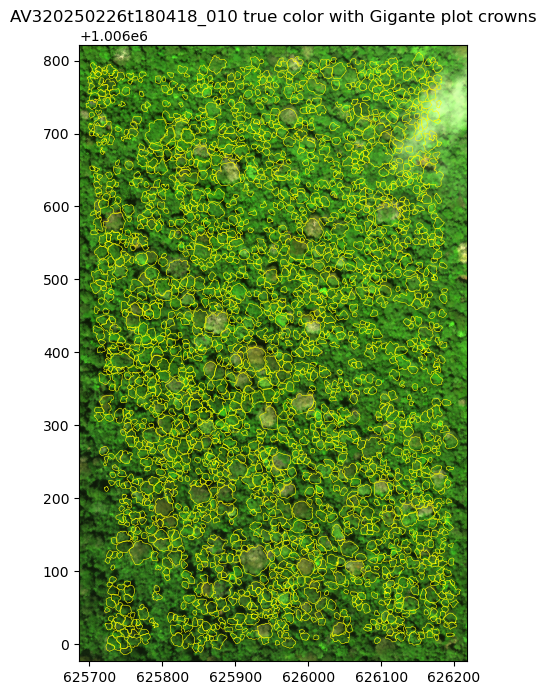

In [12]:
def true_color(da, scale=0.1):
    """Returns a true-color RGB array from a reflectance DataArray."""
    rgb = da.sel(wavelength=[650, 560, 470],
                 method='nearest').values.transpose(1, 2, 0)
    return np.clip(rgb / scale, 0, 1)

# plot extent
extent = [float(rfl_sub.x.min()), float(rfl_sub.x.max()),
          float(rfl_sub.y.min()), float(rfl_sub.y.max())]
fig, ax = plt.subplots(figsize=(14, 8))
# plot RGB
ax.imshow(true_color(rfl_sub), extent=extent)
# plot crown boundary
gigante.boundary.plot(ax=ax, color='yellow', lw=0.4)
ax.set_title(f"{scene_id} true color with Gigante plot crowns")
ax.ticklabel_format(style='plain')
plt.show()

### Check the alignment

Because the tree crowns were based on drone orthomosaics and AVIRIS-3 has its own orthorectification, pixels from the two may be offset. Before extracting spectra, we zoom in and check that the crown outlines match the crowns in the image.

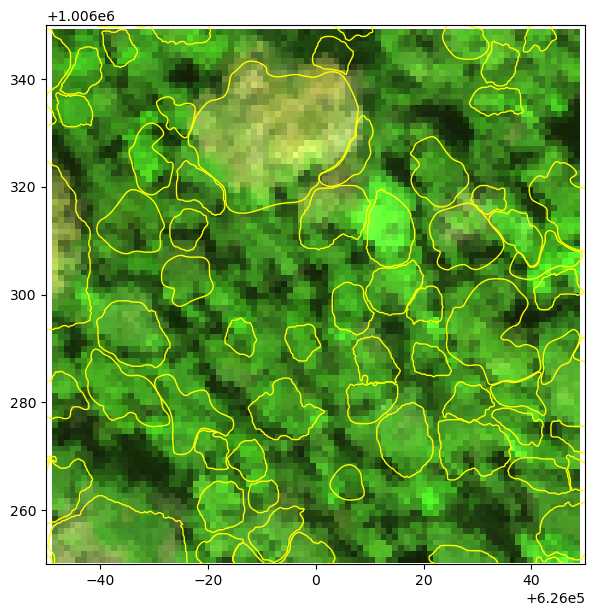

In [13]:
# 100 m x 100 m zoom
cx, cy = 626000, 1006300
zoom = rfl_sub.sel(x=slice(cx - 50, cx + 50), y=slice(cy + 50, cy - 50))
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(true_color(zoom, scale=0.08),
          extent=[float(zoom.x.min()), float(zoom.x.max()), float(zoom.y.min()), float(zoom.y.max())])
gigante.boundary.plot(ax=ax, color='yellow', lw=1)
ax.set_xlim(cx - 50, cx + 50)
ax.set_ylim(cy - 50, cy + 50)
ax.ticklabel_format(style='plain')
plt.show()

For the purpose of this tutorial, we can assume that crown outlines match the crowns in the AVIRIS-3 image relatively well. The dark areas between crowns are shadows and gaps.

## Quality Filtering

Since the provisional AVUELO L2A product has no quality flags, we build our own from the reflectance, its uncertainty, and the crown attributes. Pixel-level filters remove bands and pixels that are unreliable. Crown-level filters remove crowns whose spectra are unlikely to represent the tree.

### Bad bands

Atmospheric water vapor absorbs almost all light near 1400 nm and 1900 nm - reflectance in these bands is noisy. The edges are also noisy. We plot the mean spectrum and its mean uncertainty for the subset.

Flagged bands: [1350 1358 1365 1373 1380 1388 1395 1402 1410 1417 1425 1432 1804 1812
 1819 1827 1834 1841 1849 1856 1864 1871 1879 1886 1893 1901 1908 1916
 1923 1931 1938 1945 1953 1960 1968]
Bad bands: 47 of 284


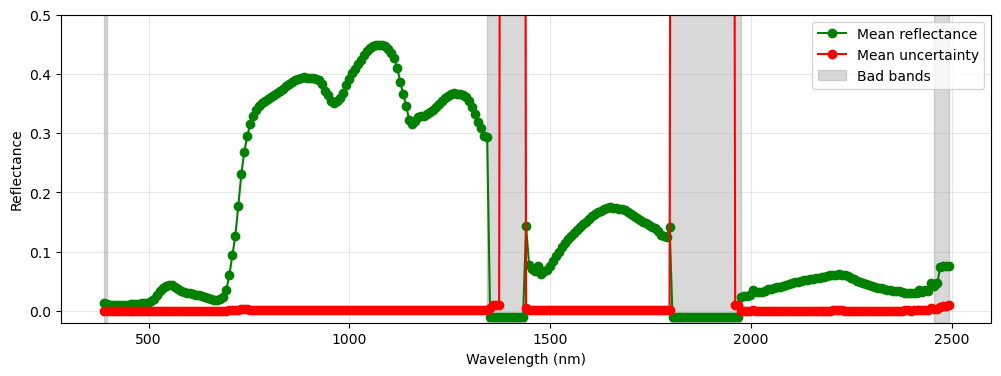

In [14]:
# wavelenth, mean RFL, UNC
wl = rfl_sub.wavelength.values
mean_rfl = rfl_sub.mean(['x', 'y']).values
mean_unc = unc_sub.mean(['x', 'y']).values

# flagging negative reflectance and large uncertainty
flagged = (mean_rfl <= 0) | (mean_unc > 0.1)
print(f"Flagged bands: {wl[flagged].round().astype(int)}")

# bad bands are flagged bands with one neighbor on each side, and the edges
bad_bands = (np.convolve(flagged, [1, 1, 1], mode='same') > 0) | (wl < 400) | (wl > 2450)
print(f"Bad bands: {bad_bands.sum()} of {len(wl)}")

# plot
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(wl, mean_rfl, 'g-o', label='Mean reflectance')
ax.plot(wl, mean_unc, 'r-o', label='Mean uncertainty')
ax.fill_between(wl, 0, 1, where=bad_bands, color='gray', alpha=0.3,
                transform=ax.get_xaxis_transform(), label='Bad bands')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Reflectance')
ax.set_ylim(-0.02, 0.5)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In the two deep water vapor absorption regions, the reflectance is set to -0.01 and the uncertainty to a very large value (~2.4). We mark these as flagged bands. The flagged bands, their neighbors, and the noisy detector edges below 400 nm and above 2450 nm are marked as bad bands, and excluded from the analysis.

### Crown pixels

Pixels at the edge of a crown often mix the crown with its neighbors or the gaps between crowns. Also, small offsets between the crown map and the image move edge pixels outside the crown. We shrink each crown by one pixel (~1.1 m) with a negative buffer, and keep only pixels whose centers fall inside the shrunk crown.

We rasterize the shrunk crowns into a label image on the AVIRIS-3 grid, where each pixel holds the ID of its crown, or 0 if outside the crowns. As crown polygons can overlap slightly, we also count the crowns over each pixel and drop pixels shared by two or more crowns.

In [15]:
# assigning crown id
gigante['crown_id'] = np.arange(1, len(gigante) + 1)
# shrinking crown area by one pixel size
pixel_size = abs(rfl_sub.rio.resolution()[0])
shrunk = gigante.geometry.buffer(-pixel_size)
shrunk = shrunk[~shrunk.is_empty]
# output raster shape/transform
shape = (rfl_sub.sizes['y'], rfl_sub.sizes['x'])
transform = rfl_sub.rio.transform()
# raster with each pixel labeled with crown id
labels = features.rasterize(zip(shrunk, gigante.loc[shrunk.index, 'crown_id']),
                            out_shape=shape, transform=transform, fill=0, dtype='int32')
# raster with each pixel as number of crowns 
n_crowns = features.rasterize(((g, 1) for g in shrunk), out_shape=shape, transform=transform,
                              fill=0, dtype='int32', merge_alg=features.MergeAlg.add)
# exclude pixels with two or more crowns
labels[n_crowns > 1] = 0

print(f"Total AVIRIS-3 pixels with tree crown: {(labels > 0).sum()}")
print(f"Total crowns with AVIRIS-3 pixels: {len(np.unique(labels)) - 1}")

Total AVIRIS-3 pixels with tree crown: 92255
Total crowns with AVIRIS-3 pixels: 1999


We extract the reflectance and uncertainty spectra of all crown pixels into 2-D arrays (pixels × bands), and keep only the good bands.

In [16]:
iy, ix = np.nonzero(labels)
good_wl = wl[~bad_bands]
pix = pd.DataFrame({'crown_id': labels[iy, ix], 'x': rfl_sub.x.values[ix], 'y': rfl_sub.y.values[iy]})
pix_rfl = rfl_sub.values[:, iy, ix].T[:, ~bad_bands]
pix_unc = unc_sub.values[:, iy, ix].T[:, ~bad_bands]
print(f"Pixel spectra: {pix_rfl.shape}")

Pixel spectra: (92255, 237)


### Pixel-level filters

We compute three pixel-level filters:

1. **NIR**: In a closed forest canopy, shaded leaves and gaps between crowns are dark in the near-infrared (NIR) region. We use the reflectance at 860 nm.
1. **NDVI**: The Normalized Difference Vegetation Index (NDVI), from the reflectance at 860 and 660 nm, is high for green leaves and low for branches, bare crowns, and soil.
1. **Uncertainty**: The median relative uncertainty (uncertainty / reflectance) over the visible bands (400–700 nm), where canopy reflectance is lowest. It is high for dark pixels and where the atmospheric correction is less certain.

In [17]:
def band(wavelength):
    """Returns index of the good band nearest to a wavelength."""
    return np.abs(good_wl - wavelength).argmin()

nir = pix_rfl[:, band(860)]
red = pix_rfl[:, band(660)]
pix['nir'] = nir
pix['ndvi'] = (nir - red) / (nir + red)
visible = (good_wl >= 400) & (good_wl <= 700)
pix['rel_unc'] = np.nanmedian(pix_unc[:, visible] / pix_rfl[:, visible], axis=1)
pix['valid'] = np.isfinite(pix_rfl).all(axis=1) & (pix_rfl >= 0).all(axis=1)
pix[pix.valid].describe()[['nir', 'ndvi', 'rel_unc']]

,nir,ndvi,rel_unc
count,92180.000000,92180.000000,92180.000000
mean,0.399321,0.894313,0.013496
std,0.092813,0.044807,0.001283
min,0.071948,0.582598,0.011400
25%,0.339112,0.884619,0.012767
50%,0.404623,0.909153,0.013230
75%,0.466232,0.922119,0.013823
max,0.694935,0.957456,0.026561


We look at the distribution of each indicator to choose thresholds.

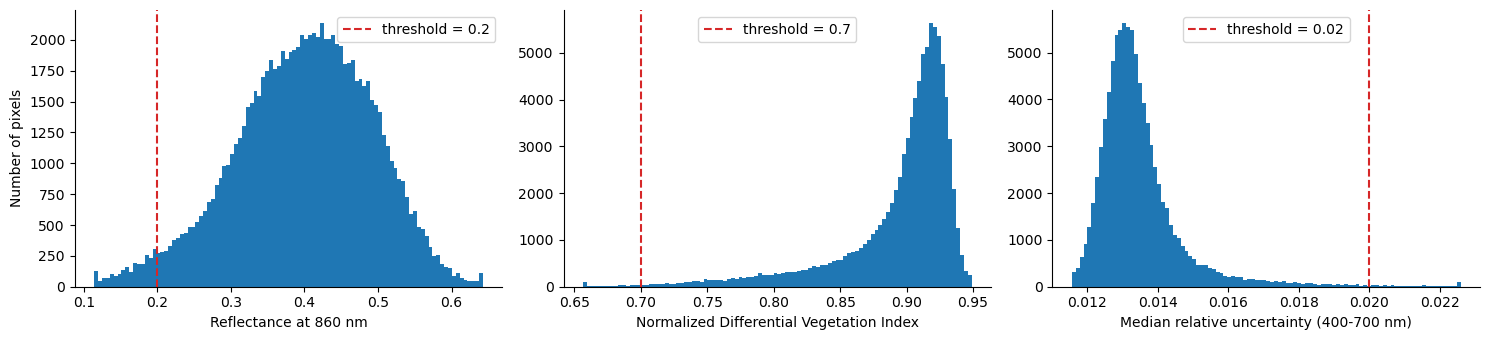

In [18]:
thresholds = {'nir': 0.2, 'ndvi': 0.7, 'rel_unc': 0.02}
labels_ = {'nir': 'Reflectance at 860 nm',
           'ndvi': 'Normalized Differential Vegetation Index',
           'rel_unc': 'Median relative uncertainty (400-700 nm)'}
v = pix[pix.valid]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (name, thr) in zip(axes, thresholds.items()):
    ax.hist(v[name].clip(*np.nanpercentile(v[name], [0.1, 99.9])), bins=100, )
    ax.axvline(thr, color='tab:red', ls='--', label=f'threshold = {thr}')
    ax.set_xlabel(labels_[name])
    ax.legend()
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Number of pixels')
plt.tight_layout()
plt.show()

The thresholds are subjective and depend on the scene and the application. (1) **NIR < 0.2**: the low tail of the NIR histogram is made of shadowed pixels and gaps between crowns. (2) **NDVI < 0.7**: almost all canopy pixels have an NDVI above 0.8. Lower values are mostly branches, leafless crowns, and mixed pixels.
(3) **Relative uncertainty > 0.02**: as the scene is clear over the plot and the uncertainty is small (1–2% of the reflectance) for nearly all pixels, this filter removes only the darkest pixels. In hazy scenes or near clouds, it removes more pixels.

We can try changing the thresholds and see how the results change.

In [19]:
pix['shadow'] = pix.nir < thresholds['nir']
pix['not_green'] = pix.ndvi < thresholds['ndvi']
pix['high_unc'] = pix.rel_unc > thresholds['rel_unc']
pix['good'] = pix.valid & ~pix.shadow & ~pix.not_green & ~pix.high_unc

We map the result for the zoomed area. Excluded pixels are mostly gaps and shaded edges between crowns.

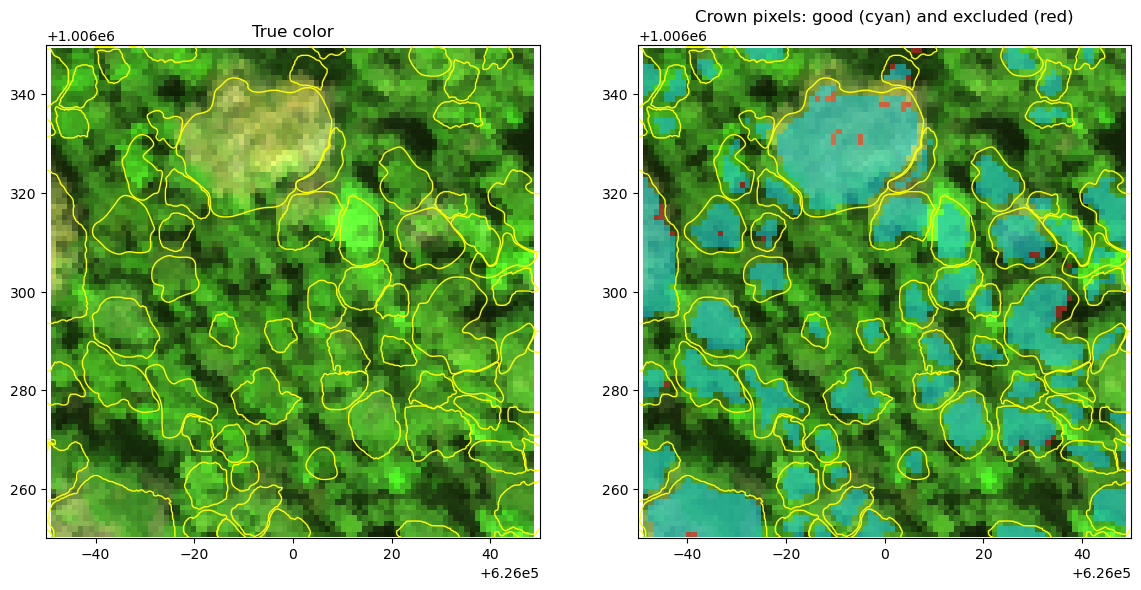

In [20]:
status = np.full(shape, np.nan)
status[iy, ix] = np.select([~pix.valid, pix.good], [np.nan, 1], 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
zx = (rfl_sub.x >= cx - 50) & (rfl_sub.x <= cx + 50)
zy = (rfl_sub.y >= cy - 50) & (rfl_sub.y <= cy + 50)
zext = [float(rfl_sub.x[zx].min()), float(rfl_sub.x[zx].max()),
        float(rfl_sub.y[zy].min()), float(rfl_sub.y[zy].max())]
axes[0].imshow(true_color(rfl_sub[:, zy.values, :][:, :, zx.values], scale=0.08), extent=zext)
axes[1].imshow(true_color(rfl_sub[:, zy.values, :][:, :, zx.values], scale=0.08), extent=zext)
axes[1].imshow(np.ma.masked_invalid(status[np.ix_(zy.values, zx.values)]), extent=zext,
               cmap=plt.matplotlib.colors.ListedColormap(['tab:red', 'tab:cyan']), alpha=0.6)
for ax in axes:
    gigante.boundary.plot(ax=ax, color='yellow', lw=1)
    ax.set_xlim(cx - 50, cx + 50)
    ax.set_ylim(cy - 50, cy + 50)
    ax.ticklabel_format(style='plain')
axes[0].set_title('True color')
axes[1].set_title('Crown pixels: good (cyan) and excluded (red)')
plt.show()

### Crown-level filters

Some crowns are poor candidates for species spectra, even if their pixels pass the filters above. Using the field attributes, we keep crowns that are (1) mostly intact (`Crown` >= 3, at least 50% intact), (2) full overhead light (`Illumination` >= 4), and (3) free or almost free of lianas (`Liana` <= 1, at most 25% liana cover). We also require at least 10 good pixels per crown.

In [21]:
min_pixels = 10
n_good = pix[pix.good].groupby('crown_id').size()
gigante['n_good_pixels'] = gigante.crown_id.map(n_good).fillna(0).astype(int)
gigante['in_scene'] = gigante.crown_id.isin(pix.loc[pix.valid, 'crown_id'])

checks = {
    'In the AVIRIS-3 scene': gigante.in_scene,
    'Crown >= 3': gigante.Crown >= 3,
    'Illumination >= 4': gigante.Illumination >= 4,
    'Liana <= 1': gigante.Liana.between(0, 1),
    f'{min_pixels}+ good pixels': gigante.n_good_pixels >= min_pixels,
}
keep = pd.Series(True, index=gigante.index)
print(f"All crowns in gigante plot: {len(gigante)} crowns")
for name, ok in checks.items():
    keep &= ok
    print(f"{name}: {keep.sum()} crowns")
gigante['selected'] = keep

All crowns in gigante plot: 2004 crowns
In the AVIRIS-3 scene: 1999 crowns
Crown >= 3: 1965 crowns
Illumination >= 4: 1716 crowns
Liana <= 1: 892 crowns
10+ good pixels: 789 crowns


## Extract Crown Spectra

For each selected crown, we compute the mean and standard deviation of the reflectance of its good pixels, and the mean uncertainty.

In [22]:
selected_ids = gigante.loc[gigante.selected, 'crown_id']
m = pix.good & pix.crown_id.isin(selected_ids)
good_cols = [f'{w:.1f}' for w in good_wl]

def crown_stats(values):
    df = pd.DataFrame(values[m.values], columns=good_cols)
    df.insert(0, 'crown_id', pix.loc[m, 'crown_id'].values)
    return df.groupby('crown_id')

crown_mean = crown_stats(pix_rfl).mean()
crown_std = crown_stats(pix_rfl).std()
crown_unc = crown_stats(pix_unc).mean()

attrs = gigante.set_index('crown_id').loc[crown_mean.index,
                                      ['Plot_tag', 'SpeciesName', 'Area_m2', 'n_good_pixels']]
print(f"Spectra extracted for {len(crown_mean)} crowns of {attrs.SpeciesName.nunique()} species")
attrs.join(crown_mean).head()

Spectra extracted for 789 crowns of 97 species


,Plot_tag,SpeciesName,Area_m2,n_good_pixels,403.0,410.4,417.8,425.3,432.7,440.1,...,2382.1,2389.5,2396.9,2404.3,2411.7,2419.1,2426.4,2433.8,2441.2,2448.6
crown_id,,,,,,,,,,,,,,,,,,,,,
1,gigante_100,Aspidosperma desmanthum,198.59,108,0.014491,0.014150,0.014468,0.014942,0.014721,0.015128,...,0.033061,0.032669,0.033169,0.032664,0.033087,0.036803,0.035416,0.039079,0.037832,0.049078
3,gigante_10059,Oenocarpus mapora,55.05,19,0.008974,0.008196,0.008464,0.008834,0.008483,0.008421,...,0.030091,0.029946,0.029978,0.029695,0.031000,0.034809,0.032171,0.035445,0.034045,0.040043
4,gigante_1012,Vatairea erythrocarpa,381.71,240,0.010304,0.009635,0.009870,0.010276,0.010178,0.010257,...,0.033895,0.033883,0.033963,0.033513,0.034620,0.037632,0.035869,0.038737,0.037375,0.047033
5,gigante_1016,Dipteryx oleifera,241.30,143,0.008338,0.007682,0.007926,0.008420,0.008268,0.008498,...,0.028924,0.028699,0.028698,0.029068,0.029321,0.034593,0.031304,0.034633,0.032338,0.042522
7,gigante_1020,Virola surinamensis,77.92,36,0.009005,0.008244,0.008353,0.008687,0.008570,0.008687,...,0.027006,0.026109,0.025649,0.026157,0.026444,0.031008,0.029077,0.031526,0.028898,0.036875


### Spectra of one crown

We plot all pixel spectra of one crown, the excluded pixels, and the crown mean with the mean uncertainty. The bad bands are left as gaps.

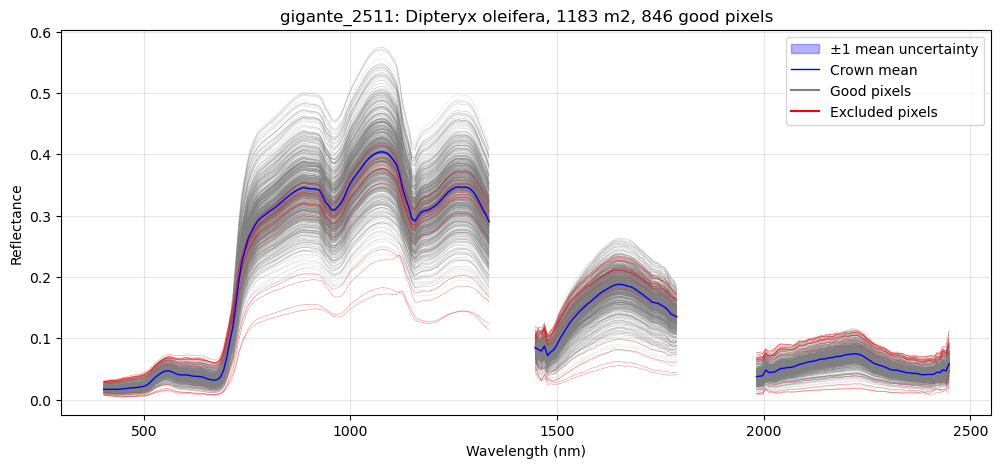

In [23]:
def with_gaps(values):
    """Inserts NaN in the bad bands for plotting."""
    full = np.full(len(wl), np.nan)
    full[~bad_bands] = values
    return full

cid = attrs.n_good_pixels.idxmax()
info = attrs.loc[cid]
in_crown = (pix.crown_id == cid).values
fig, ax = plt.subplots(figsize=(12, 5))

for i in np.where(in_crown & pix.good.values)[0]:
    ax.plot(wl, with_gaps(pix_rfl[i]), color='gray', lw=0.3, alpha=0.3)
for i in np.where(in_crown & ~pix.good.values & pix.valid.values)[0]:
    ax.plot(wl, with_gaps(pix_rfl[i]), color='red', lw=0.3, alpha=0.6)
mean = with_gaps(crown_mean.loc[cid].values)
u = with_gaps(crown_unc.loc[cid].values)
ax.fill_between(wl, mean - u, mean + u, color='blue', alpha=0.3, label='±1 mean uncertainty')
ax.plot(wl, mean, color='blue', lw=1, label='Crown mean')
ax.plot([], [], color='gray', label='Good pixels')
ax.plot([], [], color='red', label='Excluded pixels')
ax.set_title(f"{info.Plot_tag}: {info.SpeciesName}, {info.Area_m2:.0f} m2, {info.n_good_pixels} good pixels")
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Reflectance')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Compare species

We plot the mean spectrum of the six species with the most selected crowns. The shading shows +- one standard deviation across the crowns of each species.

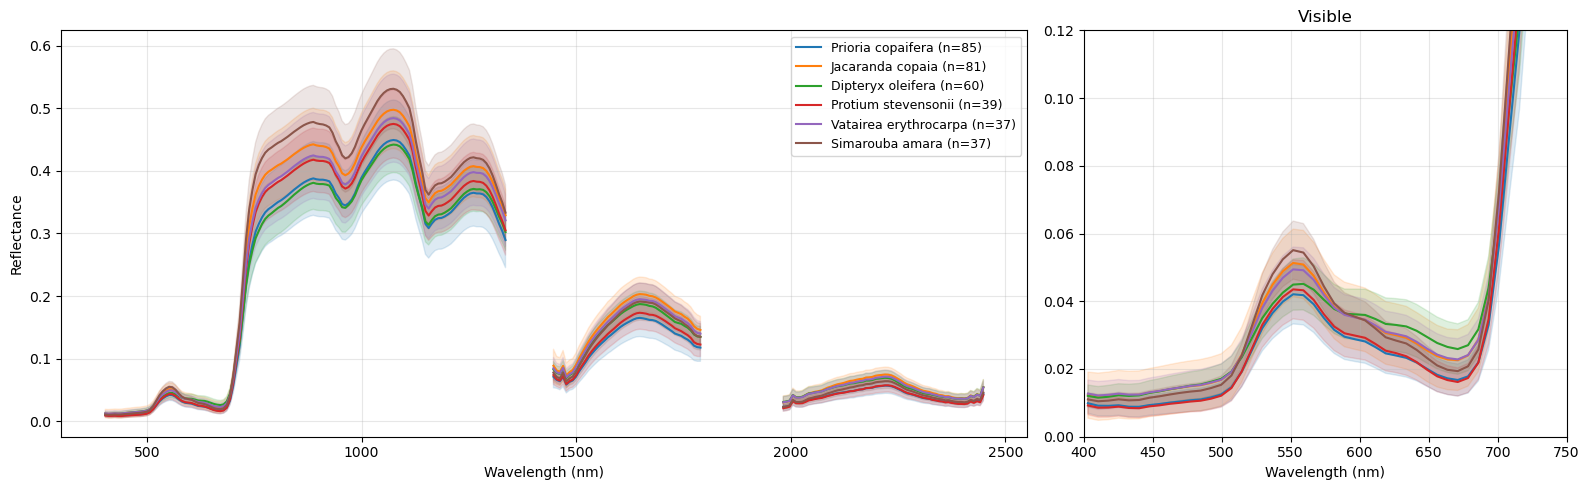

In [24]:
top_species = attrs.SpeciesName.value_counts().head(6)
colors = plt.cm.tab10.colors
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [2, 1]})
for (sp, n), color in zip(top_species.items(), colors):
    spec = crown_mean[attrs.SpeciesName == sp]
    mu, sd = with_gaps(spec.mean().values), with_gaps(spec.std().values)
    for ax in axes:
        ax.fill_between(wl, mu - sd, mu + sd, color=color, alpha=0.15)
        ax.plot(wl, mu, color=color, lw=1.5, label=f"{sp} (n={n})")
axes[0].set_ylabel('Reflectance')
axes[1].set_xlim(400, 750)
axes[1].set_ylim(0, 0.12)
axes[1].set_title('Visible')
for ax in axes:
    ax.set_xlabel('Wavelength (nm)')
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

The species differ most in brightness in the near-infrared (750–1300 nm) and shortwave infrared (1500–1800 nm) regions, which depends on leaf and canopy structure, leaf water, and illumination. They also differ in the visible region, for example in the height of the green peak near 550 nm, which depends on leaf pigments. The variation between crowns of the same species (shading) is also large compared with the differences between species. 

## Export

We save the crown mean spectra and the crown attributes as a CSV file. Each row is a crown and each reflectance column is named by its wavelength in nm. We also save the selected crown polygons, with the number of good pixels, as a GeoPackage.

In [26]:
# mean spectra
out = attrs.join(crown_mean)
out.to_csv(f'data/{scene_id}_gigante_crown_spectra.csv')
# st. dev of spectra
attrs.join(crown_std).to_csv(f'data/{scene_id}_gigante_crown_spectra_std.csv')
# selected tree crown boundary
gigante[gigante.selected].drop(columns=['in_scene', 'selected']).to_file(
    f'data/{scene_id}_gigante_selected_crowns.gpkg', driver='GPKG')